# 📐 Fundamentos: K-Means

## La idea, en una frase
> **K-Means reparte los puntos en k grupos de forma que cada punto quede lo más cerca posible del "centro" (centroide) de su grupo.**

Tú decides cuántos grupos (**k**); el algoritmo decide **qué punto va en cuál grupo** y **dónde queda cada centro**. No hay etiquetas ni respuesta correcta: sólo la geometría de los datos.

## 🧭 Contenido
| # | Tema | ¿Qué vas a ver? |
|---|---|---|
| 1 | Datos de juguete | Cuatro nubes de puntos generadas con `make_blobs` |
| 2 | El algoritmo de Lloyd, a mano | Asignar → recalcular, iteración por iteración, programado con `numpy` y comparado con `sklearn` |
| 3 | La inicialización importa | Óptimos locales, `init='random'` vs `k-means++` y `n_init` |
| 4 | ¿Cuántos clusters? | Codo y silhouette |
| 5 | Un caso con respuesta conocida: Iris | Escalar, agrupar y comparar contra las especies reales con una **tabla cruzada** |
| 6 | Cuándo K-Means falla | Lunas, círculos concéntricos y grupos de tamaños/densidades distintas |
| 7 | ⚠️ Errores comunes | Lo que más se equivoca en la práctica |

Hay **3 mini-ejercicios ✍️** en el camino.

---
# 0️⃣ Preparación

Ejecuta las siguientes celdas **una sola vez**.

## 🛠️ Funciones auxiliares de visualización

Ejecuta la siguiente celda **una sola vez** al inicio. Después sólo tienes que **llamar** a la función que necesites:

| Función | ¿Para qué sirve? |
|---|---|
| `plot_distributions(df, columnas)` | Histograma + boxplot de variables numéricas |
| `plot_correlation_matrix(df, columnas)` | Matriz de correlación |
| `plot_pairplot(df, columnas, color=None)` | Dispersión entre todas las variables numéricas |
| `plot_clusters(df, x, y, labels, centroides=None)` | Puntos en 2D coloreados por cluster (el ruido en gris) |
| `plot_clusters_3d(df, x, y, z, labels)` | Lo mismo en 3D (se puede rotar) |
| `plot_codo(ks, inercias)` | Método del codo para elegir k |
| `plot_silueta_k(tabla)` | Silhouette promedio según k |
| `plot_silueta(X, labels)` | Coeficiente de silueta de cada punto, por cluster |
| `plot_k_distancia(X, k, eps=None)` | Distancia al k-ésimo vecino: ayuda a elegir `eps` de DBSCAN |
| `plot_varianza_explicada(pca)` | Varianza explicada por componente y acumulada |
| `plot_cargas(pca, columnas)` | Peso de cada variable original en cada componente |
| `plot_biplot(scores, pca, columnas, labels=None)` | Puntos en PC1-PC2 con una flecha por variable |

In [1]:
# Funciones auxiliares de visualización
# Ejecuta esta celda una vez; después sólo llama a las funciones.
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots


def _etiquetas_texto(labels):
    """Convierte etiquetas de cluster a texto para que plotly use colores discretos; -1 = 'Ruido'."""
    labels = np.asarray(labels)
    return np.where(labels == -1, 'Ruido', np.char.add('Cluster ', labels.astype(str)))


def _orden_clusters(texto):
    """Orden de la leyenda: Cluster 0, 1, 2, … y 'Ruido' al final."""
    unicos = sorted(set(texto), key=lambda t: (t == 'Ruido', int(t.split()[-1]) if t != 'Ruido' else 0))
    return {'cluster': unicos}


def plot_distributions(df, columns, nbins=30):
    """Histograma con boxplot marginal para cada variable numérica."""
    for col in columns:
        fig = px.histogram(
            df,
            x=col,
            nbins=nbins,
            marginal='box',
            opacity=0.7,
            title=f'Distribución de {col}'
        )
        fig.update_layout(bargap=0.2)
        fig.show()


def plot_correlation_matrix(df, columns):
    """Mapa de calor con la correlación de Pearson entre las variables numéricas."""
    corr = df[columns].corr().round(2)
    fig = px.imshow(
        corr,
        text_auto=True,
        color_continuous_scale='RdBu_r',
        zmin=-1,
        zmax=1,
        title='Matriz de Correlación'
    )
    fig.update_layout(width=750, height=650)
    fig.show()


def plot_pairplot(df, columns, color=None):
    """Matriz de dispersión (pairplot) entre las variables numéricas."""
    fig = px.scatter_matrix(
        df,
        dimensions=columns,
        color=color,
        title='Pairplot de Variables Numéricas'
    )
    fig.update_layout(width=1000, height=1000, title_font_size=20)
    fig.update_traces(diagonal_visible=True, marker={'size': 4, 'opacity': 0.6})
    fig.show()


def plot_clusters(df, x, y, labels, centroides=None, title='Clusters'):
    """Dispersión 2D coloreada por cluster. El ruido de DBSCAN (-1) aparece en gris.
    centroides: arreglo (k, 2) en las mismas unidades que x, y (opcional)."""
    datos = df[[x, y]].copy()
    datos['cluster'] = _etiquetas_texto(labels)
    fig = px.scatter(
        datos,
        x=x,
        y=y,
        color='cluster',
        category_orders=_orden_clusters(datos['cluster']),
        color_discrete_map={'Ruido': 'lightgray'},
        opacity=0.8,
        title=title
    )
    if centroides is not None:
        centroides = np.asarray(centroides)
        fig.add_trace(go.Scatter(
            x=centroides[:, 0],
            y=centroides[:, 1],
            mode='markers',
            marker={'symbol': 'x', 'size': 16, 'color': 'black', 'line': {'width': 2}},
            name='Centroides'
        ))
    fig.update_layout(width=800, height=550)
    fig.show()


def plot_clusters_3d(df, x, y, z, labels, title='Clusters en 3D'):
    """Dispersión 3D coloreada por cluster (se puede rotar con el mouse)."""
    datos = df[[x, y, z]].copy()
    datos['cluster'] = _etiquetas_texto(labels)
    fig = px.scatter_3d(
        datos,
        x=x,
        y=y,
        z=z,
        color='cluster',
        category_orders=_orden_clusters(datos['cluster']),
        color_discrete_map={'Ruido': 'lightgray'},
        opacity=0.8,
        title=title
    )
    fig.update_traces(marker={'size': 4})
    fig.update_layout(width=850, height=650)
    fig.show()


def plot_codo(ks, inercias):
    """Método del codo: inercia (suma de distancias² al centroide) para cada k."""
    fig = px.line(
        x=list(ks),
        y=list(inercias),
        markers=True,
        labels={'x': 'Número de clusters (k)', 'y': 'Inercia'},
        title='Método del codo'
    )
    fig.update_layout(width=750, height=450)
    fig.show()


def plot_silueta_k(tabla):
    """Silhouette promedio para cada k (tabla de tabla_metricas_k). Más alto es mejor."""
    fig = px.line(
        tabla,
        x='k',
        y='silhouette',
        markers=True,
        labels={'k': 'Número de clusters (k)', 'silhouette': 'Silhouette promedio'},
        title='Silhouette según k (↑ mejor)'
    )
    fig.update_xaxes(dtick=1)
    fig.update_layout(width=750, height=450)
    fig.show()


def plot_silueta(X, labels, title=None):
    """Gráfica de silueta: el ancho de cada barra es el coeficiente de un punto, agrupado por cluster.
    La línea punteada es el promedio. Los puntos de ruido (-1) se excluyen."""
    from sklearn.metrics import silhouette_samples, silhouette_score

    X = np.asarray(X)
    labels = np.asarray(labels)
    mask = labels != -1
    X, labels = X[mask], labels[mask]
    valores = silhouette_samples(X, labels)
    promedio = silhouette_score(X, labels)

    fig = go.Figure()
    y_inf = 10
    for c in np.unique(labels):
        v = np.sort(valores[labels == c])
        y = np.arange(y_inf, y_inf + len(v))
        fig.add_trace(go.Scatter(
            x=v, y=y, fill='tozerox', mode='lines', line={'width': 0.5}, name=f'Cluster {c}'
        ))
        y_inf += len(v) + 10
    fig.add_vline(x=promedio, line_dash='dash', line_color='red',
                  annotation_text=f'promedio = {promedio:.3f}', annotation_position='top')
    fig.update_layout(
        title=title or f'Gráfica de silueta (k = {len(np.unique(labels))})',
        xaxis_title='Coeficiente de silueta',
        yaxis={'showticklabels': False, 'title': 'Puntos (ordenados por cluster)'},
        width=750,
        height=500
    )
    fig.show()


def plot_k_distancia(X, k, eps=None):
    """Distancia que necesita cada punto para tener k vecinos (contándose a sí mismo), ordenada.
    Usa k = min_samples: igual que DBSCAN, el punto cuenta como uno de sus k vecinos, así que un punto
    es núcleo con un eps dado si su distancia en esta curva es <= eps. El 'codo' sugiere un buen eps.
    eps (opcional) dibuja una línea horizontal de referencia."""
    from sklearn.neighbors import NearestNeighbors

    # n_neighbors=k incluye al propio punto (distancia 0), como min_samples en DBSCAN
    vecinos = NearestNeighbors(n_neighbors=k).fit(X)
    distancias, _ = vecinos.kneighbors(X)
    d_k = np.sort(distancias[:, -1])

    fig = px.line(
        x=np.arange(len(d_k)),
        y=d_k,
        labels={'x': 'Puntos ordenados por distancia', 'y': f'Distancia para tener {k} vecinos (incluido él)'},
        title=f'Gráfica de k-distancia (k = {k})'
    )
    if eps is not None:
        fig.add_hline(y=eps, line_dash='dash', line_color='red',
                      annotation_text=f'eps = {eps}', annotation_position='top left')
    fig.update_layout(width=750, height=450)
    fig.show()


def plot_varianza_explicada(pca):
    """Scree plot: varianza explicada por componente (barras) y acumulada (línea)."""
    ratio = pca.explained_variance_ratio_
    n = np.arange(1, len(ratio) + 1)
    fig = go.Figure()
    fig.add_trace(go.Bar(x=n, y=ratio, name='Por componente'))
    fig.add_trace(go.Scatter(x=n, y=np.cumsum(ratio), mode='lines+markers', name='Acumulada'))
    for umbral in (0.80, 0.95):
        fig.add_hline(y=umbral, line_dash='dot', line_color='gray',
                      annotation_text=f'{umbral:.0%}', annotation_position='right')
    fig.update_layout(
        title='Varianza explicada por componente',
        xaxis={'title': 'Componente principal', 'dtick': 1 if len(ratio) <= 30 else None},
        yaxis={'title': 'Proporción de varianza', 'tickformat': '.0%', 'range': [0, 1.05]},
        width=800,
        height=450
    )
    fig.show()


def plot_cargas(pca, columnas, n_componentes=None):
    """Mapa de calor de las cargas (loadings): cuánto pesa cada variable original en cada componente."""
    n = n_componentes or pca.n_components_
    cargas = pd.DataFrame(
        pca.components_[:n].T,
        index=columnas,
        columns=[f'PC{i + 1}' for i in range(n)]
    ).round(2)
    fig = px.imshow(
        cargas,
        text_auto=True,
        color_continuous_scale='RdBu_r',
        zmin=-1,
        zmax=1,
        aspect='auto',
        title='Cargas de cada variable en los componentes'
    )
    fig.update_layout(width=200 + 90 * n, height=150 + 40 * len(columnas))
    fig.show()


def plot_biplot(scores, pca, columnas, labels=None, escala=None, title='Biplot PC1 vs PC2'):
    """Puntos en el plano PC1-PC2 más una flecha por variable original (sus cargas).
    scores: salida de pca.transform(X). labels (opcional) colorea los puntos por cluster o grupo."""
    scores = np.asarray(scores)
    datos = pd.DataFrame({'PC1': scores[:, 0], 'PC2': scores[:, 1]})
    if labels is not None:
        datos['grupo'] = _etiquetas_texto(labels) if np.issubdtype(np.asarray(labels).dtype, np.integer) \
            else np.asarray(labels).astype(str)
    fig = px.scatter(datos, x='PC1', y='PC2', color='grupo' if labels is not None else None,
                     opacity=0.6, title=title)
    cargas = pca.components_[:2].T
    escala = escala or 0.9 * np.abs(scores[:, :2]).max() / np.abs(cargas).max()
    for (cx, cy), nombre in zip(cargas * escala, columnas):
        fig.add_annotation(x=cx, y=cy, ax=0, ay=0, xref='x', yref='y', axref='x', ayref='y',
                           showarrow=True, arrowhead=2, arrowwidth=1.5, arrowcolor='black')
        fig.add_annotation(x=cx * 1.08, y=cy * 1.08, text=nombre, showarrow=False, font={'size': 12})
    r = pca.explained_variance_ratio_
    fig.update_layout(
        xaxis_title=f'PC1 ({r[0]:.1%} de la varianza)',
        yaxis_title=f'PC2 ({r[1]:.1%} de la varianza)',
        width=850,
        height=650
    )
    fig.show()

### 🧰 Funciones de clustering

Hacen en una línea lo que de otra forma repetirías con cada modelo:

| Función | ¿Para qué sirve? |
|---|---|
| `evaluar_clustering(nombre, X, labels)` | Número de clusters, % de ruido y silhouette (sin contar el ruido) |
| `tabla_metricas_k(X, ks)` | Ajusta K-Means para cada k y regresa inercia y silhouette en una tabla |
| `perfil_clusters(df, labels, columnas)` | Tamaño y promedio de cada variable por cluster |

In [2]:
# Funciones de clustering
# Ejecuta esta celda una vez; después sólo llama a las funciones.
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


def evaluar_clustering(nombre, X, labels):
    """Silhouette de un agrupamiento. El ruido (-1) se excluye del cálculo,
    pero se reporta qué porcentaje de los puntos quedó como ruido."""
    X = np.asarray(X)
    labels = np.asarray(labels)
    mask = labels != -1
    n_clusters = len(np.unique(labels[mask]))
    fila = {
        'modelo': nombre,
        'n_clusters': n_clusters,
        'pct_ruido': float(round(100 * (~mask).mean(), 1)),
    }
    if n_clusters >= 2:
        fila['silhouette'] = float(round(silhouette_score(X[mask], labels[mask]), 3))
    else:
        fila['silhouette'] = np.nan
    return fila


def tabla_metricas_k(X, ks, random_state=42):
    """Ajusta K-Means para cada k y regresa una tabla con la inercia (para el codo) y la silhouette."""
    filas = []
    for k in ks:
        modelo = KMeans(n_clusters=k, n_init=10, random_state=random_state).fit(X)
        fila = evaluar_clustering(f'k={k}', X, modelo.labels_)
        filas.append({'k': k, 'inercia': float(round(modelo.inertia_, 1)), 'silhouette': fila['silhouette']})
    return pd.DataFrame(filas)


def perfil_clusters(df, labels, columnas):
    """Promedio de cada variable por cluster, con tamaño y porcentaje. Sirve para ponerle nombre a cada grupo."""
    datos = df[columnas].copy()
    datos['cluster'] = np.asarray(labels)
    perfil = datos.groupby('cluster')[columnas].mean().round(1)
    perfil.insert(0, 'n', datos['cluster'].value_counts().sort_index())
    perfil.insert(1, 'pct', (100 * perfil['n'] / perfil['n'].sum()).round(1))
    perfil.index = ['Ruido' if c == -1 else f'Cluster {c}' for c in perfil.index]
    return perfil

In [3]:
# Librerías que usaremos en este notebook
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_circles, make_moons, load_iris
from sklearn.preprocessing import StandardScaler

---
# 1️⃣ Datos de juguete

Empezamos con datos **inventados a propósito**: 300 puntos en 2D repartidos en 4 nubes. Sabemos de qué nube salió cada punto (`y_blobs`), pero **el algoritmo no lo sabrá**: sólo verá las coordenadas. Esa etiqueta la usaremos al final para comprobar si K-Means las encontró.

In [4]:
X_blobs, y_blobs = make_blobs(
    n_samples=300,
    centers=4,
    cluster_std=1.0,
    random_state=42
)
print(X_blobs.shape)

fig = px.scatter(
    x=X_blobs[:, 0],
    y=X_blobs[:, 1],
    labels={'x': 'x₁', 'y': 'x₂'},
    title='300 puntos sin etiqueta: ¿cuántos grupos ves?'
)
fig.update_traces(marker={'color': 'gray', 'opacity': 0.7})
fig.update_layout(width=650, height=500)
fig.show()

(300, 2)


✅ **Qué observar:** a simple vista se ven **4 nubes**. Para nosotros es obvio; el reto es escribir una receta que lo descubra sola, sin ver colores.

---
# 2️⃣ El algoritmo de Lloyd, a mano

K-Means (en su versión clásica, el **algoritmo de Lloyd**) repite dos pasos muy simples:

1. **Inicializar:** elegir k puntos al azar como centroides iniciales.
2. **Asignar:** cada punto se va con el centroide **más cercano** (distancia euclidiana).
3. **Recalcular:** cada centroide se mueve al **promedio** de los puntos que le tocaron.
4. **Repetir** 2 y 3 hasta que los centroides ya no se muevan.

¿Qué está optimizando? La **inercia** (también llamada *suma de cuadrados dentro de los clusters*):

$$J = \sum_{i=1}^{n} \lVert x_i - \mu_{c(i)} \rVert^2$$

donde $\mu_{c(i)}$ es el centroide del cluster al que pertenece el punto $x_i$. **Asignar** baja $J$ porque cada punto escoge su centro más cercano; **recalcular** baja $J$ porque el promedio es el punto que minimiza la suma de distancias al cuadrado. Como $J$ nunca sube, el algoritmo **siempre converge**… aunque no siempre al mejor resultado (lo vemos en la Parte 3).

Programemos los tres ingredientes con `numpy`:

In [5]:
def asignar(X, centroides):
    """Paso 2: índice del centroide más cercano para cada punto."""
    # distancias[i, j] = distancia² del punto i al centroide j
    distancias = ((X[:, None, :] - centroides[None, :, :]) ** 2).sum(axis=2)
    return distancias.argmin(axis=1)


def recalcular(X, labels, k):
    """Paso 3: cada centroide pasa a ser el promedio de sus puntos."""
    return np.array([X[labels == j].mean(axis=0) for j in range(k)])


def inercia(X, labels, centroides):
    """J = suma de distancias² de cada punto a su centroide."""
    return ((X - centroides[labels]) ** 2).sum()


def lloyd(X, centroides_iniciales, max_iter=20):
    """K-Means de Lloyd. Regresa la historia de centroides y etiquetas de cada iteración."""
    k = len(centroides_iniciales)
    centroides = centroides_iniciales.copy()
    historia = []
    for _ in range(max_iter):
        labels = asignar(X, centroides)
        nuevos = recalcular(X, labels, k)
        historia.append({'antes': centroides, 'labels': labels, 'despues': nuevos,
                         'inercia': inercia(X, labels, nuevos)})
        if np.allclose(nuevos, centroides):
            break
        centroides = nuevos
    return historia

Arrancamos con una inicialización **a propósito difícil**: 4 puntos al azar (semilla 33) que caen **todos en la misma nube**. Veamos si el algoritmo se recupera.

In [6]:
rng = np.random.default_rng(33)
idx_inicio = rng.choice(len(X_blobs), size=4, replace=False)
centroides_0 = X_blobs[idx_inicio]

historia = lloyd(X_blobs, centroides_0)
for t, paso in enumerate(historia, start=1):
    print(f"Iteración {t}: inercia J = {paso['inercia']:.1f}")

Iteración 1: inercia J = 13417.7
Iteración 2: inercia J = 8398.3
Iteración 3: inercia J = 3834.7
Iteración 4: inercia J = 564.9
Iteración 5: inercia J = 564.9


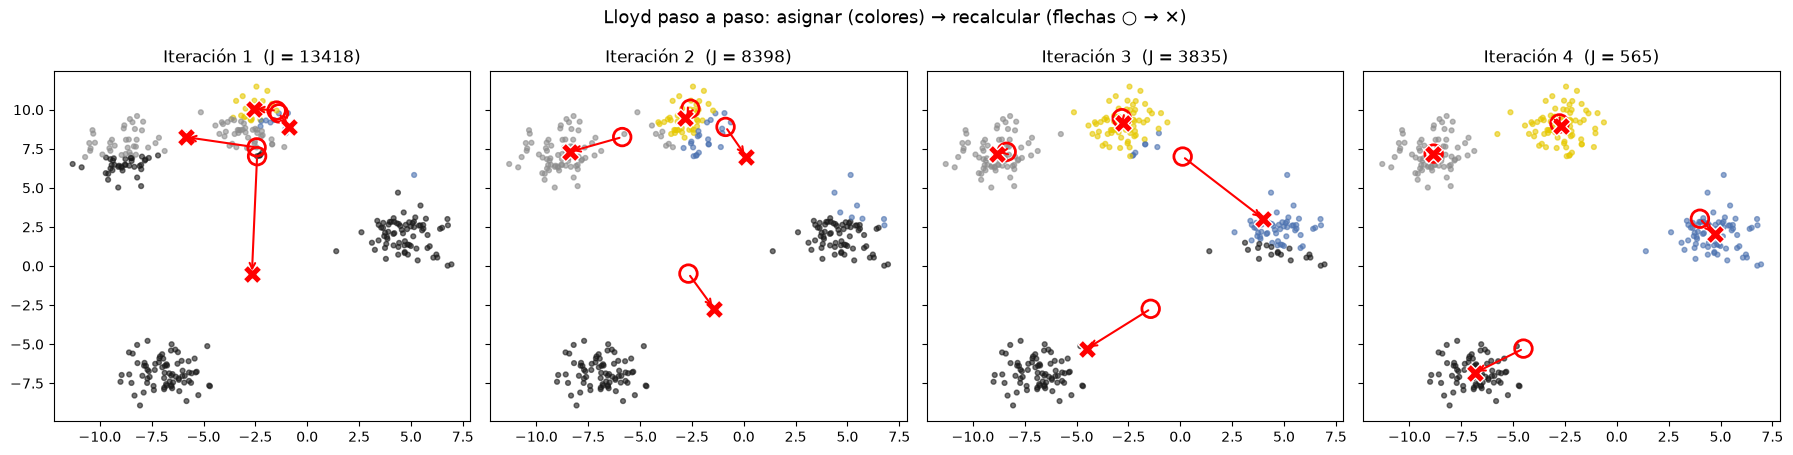

In [7]:
# Las primeras 4 iteraciones: color = cluster asignado, ○ = centroide antes, ✕ = después
fig, axes = plt.subplots(1, 4, figsize=(18, 4.6), sharex=True, sharey=True)
colores = np.array(['#1A1A1A', '#E6C800', '#8C8C8C', '#4C72B0'])
for t, ax in enumerate(axes):
    paso = historia[t]
    ax.scatter(X_blobs[:, 0], X_blobs[:, 1], c=colores[paso['labels']], s=12, alpha=0.6)
    ax.scatter(paso['antes'][:, 0], paso['antes'][:, 1], s=160, facecolors='none',
               edgecolors='red', linewidths=2)
    ax.scatter(paso['despues'][:, 0], paso['despues'][:, 1], marker='X', s=180,
               c='red', edgecolors='white')
    for a, d in zip(paso['antes'], paso['despues']):
        ax.annotate('', xy=d, xytext=a, arrowprops={'arrowstyle': '->', 'color': 'red', 'lw': 1.5})
    ax.set_title(f"Iteración {t + 1}  (J = {paso['inercia']:.0f})")
fig.suptitle('Lloyd paso a paso: asignar (colores) → recalcular (flechas ○ → ✕)', fontsize=13)
plt.tight_layout()
plt.show()

✅ **Qué observar:** (la $ de cada título se calcula **después** de recalcular los centroides)
- En la **iteración 1** los 4 centroides iniciales (○) están en la nube de arriba al centro. Las nubes de abajo y de la derecha se van completas con un mismo centroide (negro), que al recalcular cae **en medio de la nada**, entre las dos (flecha larga hacia abajo). La inercia es altísima: **J = 13,418**.
- En las iteraciones **2 y 3** los centroides se van "repartiendo" las nubes: J baja a **8,398** y luego a **3,835**.
- En la **iteración 4** cada nube ya tiene su propio centroide y $ = **564.9**. En la iteración 5 nadie cambia de cluster: el algoritmo **convergió**. Se recuperó de un mal arranque.
- La inercia **sólo baja**, nunca sube: es la garantía de convergencia de Lloyd.

Ahora comparemos nuestra versión con la de `sklearn`:

In [8]:
kmeans_blobs = KMeans(n_clusters=4, n_init=10, random_state=42).fit(X_blobs)

centroides_mano = historia[-1]['despues']
print(f"Inercia a mano:   {historia[-1]['inercia']:.1f}")
print(f"Inercia sklearn:  {kmeans_blobs.inertia_:.1f}")
print(f"Iteraciones a mano: {len(historia)}  |  sklearn: {kmeans_blobs.n_iter_}")

# Ordenamos los centroides por su primera coordenada para compararlos (el número de cluster es arbitrario)
centroides_sk = kmeans_blobs.cluster_centers_
print('\nCentroides a mano:\n', np.round(centroides_mano[np.argsort(centroides_mano[:, 0])], 2))
print('Centroides sklearn:\n', np.round(centroides_sk[np.argsort(centroides_sk[:, 0])], 2))

Inercia a mano:   564.9
Inercia sklearn:  564.9
Iteraciones a mano: 5  |  sklearn: 2

Centroides a mano:
 [[-8.87  7.17]
 [-6.83 -6.83]
 [-2.71  8.97]
 [ 4.72  2.04]]
Centroides sklearn:
 [[-8.87  7.17]
 [-6.83 -6.83]
 [-2.71  8.97]
 [ 4.72  2.04]]


✅ **Qué observar:** nuestra implementación de ~20 líneas llega **a la misma inercia (564.9) y a los mismos centroides** que `sklearn`. `KMeans` hace exactamente esto, con dos mejoras: una inicialización más inteligente y varios intentos (Parte 3).

> 💡 El número de cada cluster (0, 1, 2, 3) es **arbitrario**: si corres con otra semilla, el "Cluster 0" puede ser otra nube. Lo que importa es **quién queda con quién**.

### ✍️ Mini-ejercicio 1: la inercia de `sklearn`

`kmeans_blobs.inertia_` es la misma $J$ que calculamos a mano. Compruébalo con nuestra función `inercia`.

In [ ]:
# 1. Llama a inercia(X, labels, centroides) con kmeans_blobs.labels_ y kmeans_blobs.cluster_centers_
# 2. Imprime el resultado junto a kmeans_blobs.inertia_
# ✍️ Tu código aquí


✍️ **¿Qué observas?** ¿Coinciden los dos valores? Explica con tus palabras qué mide la inercia.

RELLENAR CON TUS COMENTARIOS

---
# 3️⃣ La inicialización importa

Lloyd siempre converge, pero **a dónde** llega depende de dónde empezó. Probemos otro arranque al azar, igual de inocente que el anterior:

In [ ]:
rng = np.random.default_rng(0)
centroides_malos = X_blobs[rng.choice(len(X_blobs), size=4, replace=False)]
historia_mala = lloyd(X_blobs, centroides_malos)
print(f"Convergió en {len(historia_mala)} iteraciones con inercia J = {historia_mala[-1]['inercia']:.1f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), sharex=True, sharey=True)
for ax, h, titulo in [(axes[0], historia, 'Arranque semilla 33'), (axes[1], historia_mala, 'Arranque semilla 0')]:
    final = h[-1]
    ax.scatter(X_blobs[:, 0], X_blobs[:, 1], c=colores[final['labels']], s=12, alpha=0.6)
    ax.scatter(final['despues'][:, 0], final['despues'][:, 1], marker='X', s=200, c='red', edgecolors='white')
    ax.set_title(f"{titulo}: J = {final['inercia']:.1f}")
fig.suptitle('Mismo algoritmo, mismos datos, distinto punto de partida', fontsize=13)
plt.tight_layout()
plt.show()

🚩 **Algo no cuadra:** con la semilla 0 el algoritmo **también convergió** (los centroides dejaron de moverse), pero a una solución peor: **dos nubes comparten un centroide** y otra nube quedó partida en dos. Su inercia es **2,060.5**, casi 4 veces la de la solución buena (**564.9**).

Esto es un **óptimo local**: ningún paso de Lloyd puede mejorarlo, porque mover un centroide de una nube a otra requeriría "subir" la inercia temporalmente.

### Dos remedios que usa `sklearn`
- **`init='k-means++'`** (el default): el primer centroide es al azar, pero cada siguiente se elige con probabilidad proporcional a la **distancia²** al centroide más cercano ya elegido. Así los centroides iniciales tienden a quedar **separados** entre sí.
- **`n_init`**: corre el algoritmo varias veces con arranques distintos y se queda con el de **menor inercia**.

Midámoslo: 20 semillas distintas, con un solo intento (`n_init=1`) cada una.

In [ ]:
filas = []
for semilla in range(20):
    aleatorio = KMeans(n_clusters=4, init='random', n_init=1, random_state=semilla).fit(X_blobs)
    plus = KMeans(n_clusters=4, init='k-means++', n_init=1, random_state=semilla).fit(X_blobs)
    filas.append({'semilla': semilla, 'inercia_random': round(aleatorio.inertia_, 1),
                  'inercia_kmeans++': round(plus.inertia_, 1)})
inits = pd.DataFrame(filas)

mejor = inits[['inercia_random', 'inercia_kmeans++']].min().min()
print(f"Mejor inercia encontrada: {mejor:.1f}")
print(f"init='random'    llega al óptimo en {(inits['inercia_random'] <= mejor + 0.1).sum()} de 20 semillas")
print(f"init='k-means++' llega al óptimo en {(inits['inercia_kmeans++'] <= mejor + 0.1).sum()} de 20 semillas")
inits.head(10)

✅ **Qué observar:**
- Con `init='random'` y un solo intento, sólo **8 de 20** semillas llegan a la solución buena (564.9); las demás se quedan atascadas en óptimos locales (~2,060 o peores).
- Con `k-means++` las **20 de 20** llegan al óptimo: separar los centroides iniciales hace casi imposible empezar con dos en la misma nube.
- En datos reales (más dimensiones, grupos menos claros) k-means++ **no es infalible**; por eso en este curso usamos siempre `n_init=10` y `random_state=42`.

> 💡 En scikit-learn 1.4+ el default es `n_init='auto'`, que con k-means++ hace **un solo** intento. Escribir `n_init=10` explícito es más seguro y deja claro qué hiciste.

### ✍️ Mini-ejercicio 2: `n_init` al rescate

La semilla 2 con `init='random'` y `n_init=1` cae en un óptimo local. Repite ese mismo modelo pero con **`n_init=10`** y compara la inercia.

In [ ]:
un_intento = KMeans(n_clusters=4, init='random', n_init=1, random_state=2).fit(X_blobs)
print(f"init='random', n_init=1:  inercia = {un_intento.inertia_:.1f}")

# 1. diez_intentos = KMeans(n_clusters=4, init='random', n_init=10, random_state=2).fit(X_blobs)
# 2. Imprime diez_intentos.inertia_
# ✍️ Tu código aquí


✍️ **¿Qué observas?** ¿Cuánto bajó la inercia? ¿Por qué 10 intentos con arranque aleatorio arreglan el problema?

RELLENAR CON TUS COMENTARIOS

---
# 4️⃣ ¿Cuántos clusters? Codo y silhouette

Hasta ahora le dijimos a K-Means que buscara **4** grupos porque *sabíamos* la respuesta. En la vida real no la sabemos. Ajustamos K-Means para varios k y miramos dos señales:

| Señal | ¿Qué mide? | ¿Qué buscamos? |
|---|---|---|
| **Inercia** (codo) | Qué tan apretados están los puntos en su cluster. **Siempre baja** al subir k | El "codo": donde deja de bajar mucho |
| **Silhouette** | Para cada punto: $s = \frac{b - a}{\max(a, b)}$, con $a$ = distancia media a su propio cluster y $b$ = al cluster vecino. Va de -1 a 1 | **Alto** |

`tabla_metricas_k` hace todo en una línea (con `n_init=10` y `random_state=42`):

In [9]:
metricas_blobs = tabla_metricas_k(X_blobs, range(2, 9))
metricas_blobs

,k,inercia,silhouette
0,2,9416.2,0.590
1,3,2110.4,0.757
2,4,564.9,0.792
3,5,512.4,0.689
4,6,460.3,0.551
5,7,408.9,0.430
6,8,360.8,0.337


In [10]:
plot_codo(metricas_blobs['k'], metricas_blobs['inercia'])
plot_silueta_k(metricas_blobs)

✅ **Qué observar:**
- **Codo:** la inercia cae de 9,416 (k=2) a 2,110 (k=3) y a **565 (k=4)**; después apenas baja (512 con k=5). El codo está en **k = 4**.
- La **silhouette** también es máxima en **k = 4** (**0.792**): codo y silhouette **coinciden**.
- Aquí todo cuadra porque los datos son de juguete. En el caso Mall verás que las señales **no siempre** son tan claras.

### La gráfica de silueta: el promedio no lo es todo
El silhouette promedio resume en un número; la **gráfica de silueta** muestra el valor de **cada punto**, agrupado por cluster. Comparemos k = 4 con k = 5:

In [11]:
plot_silueta(X_blobs, kmeans_blobs.labels_, title='Silueta con k = 4')

kmeans_blobs_5 = KMeans(n_clusters=5, n_init=10, random_state=42).fit(X_blobs)
plot_silueta(X_blobs, kmeans_blobs_5.labels_, title='Silueta con k = 5')

✅ **Qué observar:**
- Con **k = 4** los cuatro clusters tienen tamaños parecidos y casi todos los puntos superan el promedio (**0.792**).
- Con **k = 5** una nube se partió en dos: esos dos clusters tienen siluetas **bajas** (sus puntos están casi igual de cerca del cluster vecino) y el promedio baja a **0.689**.
- Una barra que no llega a la línea roja, o valores **negativos**, avisan de clusters forzados o puntos mal asignados.

---
# 5️⃣ Un caso con respuesta conocida: Iris

El dataset **Iris** tiene 150 flores de **3 especies** con 4 medidas en cm (largo y ancho del sépalo y del pétalo). Haremos como si **no** supiéramos la especie, agruparemos con K-Means y al final compararemos contra la especie real.

Para comparar los clusters con las especies usamos una **tabla cruzada** (`pd.crosstab`): cada fila es una especie, cada columna un cluster, y cada celda cuenta cuántas flores caen ahí. Si K-Means encontró las especies, cada fila tendrá casi todas sus flores en **una sola columna**. Los nombres de los clusters no importan (que el "Cluster 0" sea *setosa* o *virginica* da igual): importa **quién queda con quién**.

> ⚠️ Esta comparación necesita la respuesta correcta. En un problema real de segmentación **no la tienes**; aquí la usamos sólo para aprender.

In [ ]:
iris = load_iris(as_frame=True)
df_iris = iris.frame.rename(columns={
    'sepal length (cm)': 'largo_sepalo',
    'sepal width (cm)': 'ancho_sepalo',
    'petal length (cm)': 'largo_petalo',
    'petal width (cm)': 'ancho_petalo',
})
df_iris['especie'] = iris.target_names[iris.target]
COLS_IRIS = ['largo_sepalo', 'ancho_sepalo', 'largo_petalo', 'ancho_petalo']

df_iris[COLS_IRIS].describe().round(2)

Las 4 medidas están en cm pero con **rangos distintos** (el largo del pétalo va de 1 a 6.9; el ancho, de 0.1 a 2.5). K-Means usa distancias, así que **escalamos** para que cada medida pese lo mismo:

In [ ]:
scaler_iris = StandardScaler()
X_iris = scaler_iris.fit_transform(df_iris[COLS_IRIS])

metricas_iris = tabla_metricas_k(X_iris, range(2, 7))
metricas_iris

🤔 **La silhouette prefiere k = 2** (**0.582** contra **0.460** con k = 3). ¿Por qué, si hay 3 especies? Porque *setosa* está muy separada, pero *versicolor* y *virginica* se **traslapan**: geométricamente, lo más claro son 2 grupos. La silhouette premia la **geometría**, no la biología.

Usamos k = 3 porque **sabemos** que hay 3 especies (sentido del problema) y vemos qué tanto se parecen los clusters a las especies:

In [ ]:
kmeans_iris = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X_iris)
cruce_iris = pd.crosstab(df_iris['especie'], kmeans_iris.labels_, rownames=['especie'], colnames=['cluster'])

# En cada cluster "manda" la especie con más flores; las demás flores de ese cluster
# quedan fuera del grupo de su especie
fuera_iris = len(df_iris) - cruce_iris.max(axis=0).sum()
print(f"Flores fuera del grupo de su especie (escalado): {fuera_iris} de {len(df_iris)}")

cruce_iris

In [ ]:
# Una sola figura: especies reales (izquierda) vs clusters de K-Means (derecha)
fig = make_subplots(rows=1, cols=2, subplot_titles=['Especie real', f'K-Means k = 3 ({fuera_iris} flores fuera de su especie)'],
                    shared_yaxes=True)
for especie in iris.target_names:
    m = df_iris['especie'] == especie
    fig.add_trace(go.Scatter(x=df_iris.loc[m, 'largo_petalo'], y=df_iris.loc[m, 'ancho_petalo'],
                             mode='markers', name=especie, legendgroup='especie',
                             legendgrouptitle_text='Especie'), row=1, col=1)
for c in range(3):
    m = kmeans_iris.labels_ == c
    fig.add_trace(go.Scatter(x=df_iris.loc[m, 'largo_petalo'], y=df_iris.loc[m, 'ancho_petalo'],
                             mode='markers', marker={'symbol': 'diamond'}, name=f'Cluster {c}',
                             legendgroup='cluster', legendgrouptitle_text='K-Means'), row=1, col=2)
fig.update_xaxes(title_text='largo del pétalo (cm)')
fig.update_yaxes(title_text='ancho del pétalo (cm)', row=1, col=1)
fig.update_layout(width=1050, height=480, title='Iris: ¿encontró K-Means las especies?')
fig.show()

✅ **Qué observar:**
- *Setosa* queda **sola y completa** en un cluster (50 de 50): está muy separada de las otras dos.
- El error está entre *versicolor* y *virginica*: **11 versicolor** caen con la mayoría de las virginica y **14 virginica** con las versicolor. Justo donde las nubes se traslapan.
- En total, **25 de 150** flores (11 + 14) quedan fuera del grupo de su especie: K-Means acierta en lo grueso, pero no es perfecto. Ojo: K-Means vio las 4 medidas, pero la figura muestra sólo 2 (las del pétalo).

### ✍️ Mini-ejercicio 3: ¿y si no escalamos?

Ajusta el mismo K-Means (k = 3, `n_init=10`, `random_state=42`) sobre las medidas **originales** `df_iris[COLS_IRIS]`, cruza sus clusters con la especie y cuenta cuántas flores quedan fuera del grupo de su especie.

In [ ]:
# 1. kmeans_iris_crudo = KMeans(n_clusters=3, n_init=10, random_state=42).fit(df_iris[COLS_IRIS])
# 2. cruce_crudo = pd.crosstab(df_iris['especie'], kmeans_iris_crudo.labels_, rownames=['especie'], colnames=['cluster'])
# 3. fuera_crudo = len(df_iris) - cruce_crudo.max(axis=0).sum()   (igual que con el modelo escalado)
#    e imprímelo junto a fuera_iris
# 4. Imprime la desviación estándar de cada medida: df_iris[COLS_IRIS].std()
# 5. Muestra cruce_crudo
# ✍️ Tu código aquí


✍️ **¿Qué observas?** Sin escalar, ¿quedan más o menos flores fuera del grupo de su especie? ¿Qué especie cambió? Mira las desviaciones estándar: ¿qué medida domina la distancia sin escalar? ¿Es buena o mala noticia en este caso? ¿Qué pasaría si una medida estuviera en mm en vez de cm?

RELLENAR CON TUS COMENTARIOS

---
# 6️⃣ Cuándo K-Means falla

K-Means asigna cada punto a su centroide más cercano. Eso implica que **las fronteras entre clusters son rectas** (cada cluster es una "celda" alrededor de su centro) y que prefiere grupos **redondos y de tamaño parecido**. Veamos tres casos donde eso no se cumple, con la respuesta correcta conocida para compararla con una tabla cruzada:

In [12]:
X_lunas, y_lunas = make_moons(n_samples=300, noise=0.05, random_state=42)
X_circulos, y_circulos = make_circles(n_samples=300, noise=0.05, factor=0.5, random_state=42)
X_tamanos, y_tamanos = make_blobs(
    n_samples=[400, 50, 50],
    centers=[[0, 0], [4, 4], [4, -4]],
    cluster_std=[2.0, 0.4, 0.4],
    random_state=42
)

casos = [('Lunas', X_lunas, y_lunas, 2),
         ('Círculos concéntricos', X_circulos, y_circulos, 2),
         ('Tamaños y densidades distintas', X_tamanos, y_tamanos, 3)]

fig = make_subplots(rows=2, cols=3, vertical_spacing=0.12,
                    subplot_titles=[c[0] + ' (real)' for c in casos] + ['K-Means'] * 3)
paleta = np.array(['#1A1A1A', '#E6C800', '#8C8C8C'])
resultados_limites = []
cruces_limites = {}
for j, (nombre, X, y, k) in enumerate(casos, start=1):
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X)
    cruces_limites[nombre] = pd.crosstab(y, labels, rownames=['grupo real'], colnames=['cluster'])
    resultados_limites.append({'caso': nombre, 'k': k,
                               'silhouette_kmeans': evaluar_clustering(nombre, X, labels)['silhouette'],
                               'silhouette_real': evaluar_clustering(nombre, X, y)['silhouette']})
    for fila, etiquetas in [(1, y), (2, labels)]:
        fig.add_trace(go.Scatter(x=X[:, 0], y=X[:, 1], mode='markers', showlegend=False,
                                 marker={'size': 5, 'color': paleta[etiquetas], 'opacity': 0.7}),
                      row=fila, col=j)
fig.update_layout(width=1100, height=700, title='Tres formas de engañar a K-Means')
fig.show()

pd.DataFrame(resultados_limites)

,caso,k,silhouette_kmeans,silhouette_real
0,Lunas,2,0.488,0.331
1,Círculos concéntricos,2,0.353,0.110
2,Tamaños y densidades distintas,3,0.417,0.381


In [ ]:
# Tabla cruzada grupo real × cluster de K-Means en cada caso
for nombre, cruce in cruces_limites.items():
    print(nombre)
    display(cruce)

✅ **Qué observar:**
- **Lunas:** K-Means corta con una línea recta y mezcla las puntas de cada luna: **75 de 300** puntos (37 + 38) quedan en el cluster de la otra luna. Las lunas no son "redondas" alrededor de un centro.
- **Círculos:** ¡los dos círculos tienen **el mismo centro**! Ningún par de centroides los separa; K-Means parte el plano en dos mitades y **cada círculo queda partido casi a la mitad** (75/75 y 76/74): el resultado no tiene nada que ver con los anillos.
- **Tamaños y densidades distintas:** las dos nubes chicas quedan completas (50 de 50 cada una), pero la nube grande y dispersa se reparte entre los tres centroides: sólo **268 de sus 400** puntos quedan juntos; las fronteras rectas a medio camino entre centroides le "roban" **132** puntos (59 + 73) para las nubes chicas.
- 🚩 En las lunas, el silhouette de K-Means (**0.488**) es **mayor** que el de la respuesta correcta (**0.331**); en los círculos pasa lo mismo (**0.353** vs **0.110**). El silhouette también premia grupos redondos: **una métrica interna alta no garantiza que encontraste la estructura real.**

> 💡 **Puente a la siguiente sesión:** **DBSCAN** no busca centros sino **zonas densas** conectadas. Puede seguir la forma de una luna, separar anillos y, además, marcar como **ruido** los puntos que no encajan en ningún grupo.

---
# 7️⃣ ⚠️ Errores comunes

| Error | Por qué es un problema | Qué hacer |
|---|---|---|
| **No escalar** las variables | La variable con números más grandes (ingreso en pesos vs edad en años) decide sola los clusters | `StandardScaler` antes de K-Means; reporta los perfiles en unidades originales |
| Usar un solo intento (`n_init=1` o `'auto'`) | Puedes quedarte en un óptimo local (Parte 3) | `n_init=10` y `random_state=42` explícitos |
| Elegir k **sólo** con el codo | El codo muchas veces es ambiguo | Mira codo + silhouette (promedio y gráfica de silueta) **y** el sentido de negocio; di cuándo no coinciden |
| Comparar inercias con distinto k | La inercia **siempre** baja al subir k (con k = n vale 0) | Usa la inercia sólo para el codo; para comparar k usa la silhouette, que no premia más clusters |
| Interpretar el **número** del cluster | "Cluster 0" no significa nada; cambia con la semilla | Ponle **nombre** según su perfil (promedios por cluster) |
| Usar K-Means con formas raras o mucho ruido | Fronteras rectas y centros arrastrados por atípicos (Parte 6) | Grafica antes; prueba DBSCAN |
| Meter variables categóricas codificadas 0/1 sin pensar | Una dummy escalada puede dominar la distancia y partir los grupos por esa variable | Úsalas sólo si tienen sentido para el negocio; perfílalas **después** de agrupar |

## 📝 Resumen
1. K-Means alterna **asignar** (punto → centroide más cercano) y **recalcular** (centroide → promedio) hasta que nada cambia; minimiza la **inercia** $J$.
2. Siempre converge, pero puede caer en un **óptimo local**: k-means++ y `n_init=10` lo evitan.
3. **k lo eliges tú**: usa varias señales y el sentido del problema.
4. **Escala** antes de agrupar y piensa qué variables entran.
5. Funciona con grupos **redondos y parecidos**; con formas raras, densidades distintas o ruido, mira DBSCAN.